# Numpyro

In [1]:
import os
#os.environ["XLA_FLAGS"] = "--xla_force_host_platform_device_count=4"

import numpyro
numpyro.set_host_device_count(4)
import jax
import jax.numpy as jnp
import jax.scipy as jscipy
import jax.random as jrand 

import numpyro.distributions as dist
from jax import vmap
from jax import jit
from jax import lax

import h5py
import json
import seaborn as sns
import numpy as np

from numpyro.infer import MCMC, NUTS, init_to_value

import arviz as az

import matplotlib.pyplot as plt

/mnt/home/hsiegel/frb_bayesian_analysis/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Constants

In [2]:
#constants
k_DM = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s

## Model

In [3]:
def setup_model(constants_dict,freqs_channels,times):
    """
        Setting up the necessary constants for the model itself. The model will be written as a closure within the setup method.
        
        constants_dict: dict of each constant in the model
        freq_channels: array of frequency channels in the data
        times: array of time bins in the data
    """


    ### We are setting up constant values here
    det_response = jnp.float32(1) # TO-DO: WILL BE FUNCTION LATER !!!! Maybe also convolution is involved if frequencies are not independent between channels
    freq_channels_ref = jnp.float32(constants_dict["freq_channels_ref"]) # fixed reference / pivot EM frequency nu_r, set approximately equal to frequency of peak emission for a pulse with Gaussian-like SED in the dynamic spectrum element D_kn
    # tau_ref = jnp.float32(constants_dict["tau_ref"]) # fixed scatter broadening timescale at freq_ref; if 0, no scatter is put in the model
    delta = jnp.float32(constants_dict["delta"])
    k_DM = jnp.float32(constants_dict["k_DM"])# dispersion constant, (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s
    epsilon = jnp.float32(constants_dict["epsilon"]) # Exponent of frequency dependence for pulse dispersion - for now it seems the model only actually allows this to be a constant -2, due to units.
    normalized_freqs_channels = freqs_channels/freq_channels_ref # nu_k / nu_r
    log_normalized_freqs_channels = jnp.log(normalized_freqs_channels)

    ## Defining things related to Fourier domain
    L = times[0].shape[0]
    dt = times[0][1] - times[0][0]
    fourier_freqs = jnp.fft.rfftfreq(L, d=dt,dtype=jnp.float32)[None, :]
    
    def single_pulse_model(params_dict):
            """
                Model of a single pulse, which will be summed in the forward model for multi-pulse signals.
                
                params_dict: dict of each parameter of the pulse
                freqs: array of frequency bins in the data
                times: array of time bins in the data
            """
        
            # frequency array nu_k
            # shape of (nfreq,1), units of MHz, these are the rows of the model matrix
            # freqs = jnp.asarray(freq_array, dtype=jnp.float32)[:, None]
            
            # time array t_n
            # shape of (1,ntime), units of seconds, these are the columns of the model matrix
            # times = jnp.asarray(time_array, dtype=jnp.float32)[None, :]
        
            #params
            alpha = jnp.float32(params_dict["alpha"]) # Base-10 exponent of amplitude for burst componnent
            gamma = jnp.float32(params_dict["gamma"]) # Spectral index for burst component
            beta = jnp.float32(params_dict["beta"]) # Spectral running for burst component
            # delta = jnp.float32(params_dict["delta"]) # Exponent of frequency dependence for scatter-broadening
            mean_arrival_time = jnp.float32(params_dict["mean_arrival_time"]) # defined so that the pulse peaks at freq_ref at this time (before scatter or dispersion shifts at other frequencies)
            sigma = jnp.float32(params_dict["sigma"]) #width of gaussian in pulse, without scatter-broadening
            DM = jnp.float32(params_dict["DM"]) # dispersion measure, pc/cm^3
            tau_ref = jnp.float32(params_dict["tau_ref"]) # scatter broadening timescale at freq_ref, if 0 then no scatter is put in the model, s

            # model
            A = 10**alpha
        
            kappa = gamma + ( beta * log_normalized_freqs_channels ) #Running power law of SED
            F = (normalized_freqs_channels**kappa) * det_response
        
            mean_time_gaussian = mean_arrival_time + ( k_DM * DM * ( (freqs_channels**epsilon) - (freq_channels_ref**epsilon) ) ) #mean time in the gaussian model with no scatter broadening
            
            taus = tau_ref * (normalized_freqs_channels ** delta) # Timescale of scattering-broadening at nu_k

            ### TO-DO : REMOVE THE FACTORS OUT FRONT IN T, THEY RENORMALIZE JUST FOR COMPARISON WITH FITBURST
            T = jnp.sqrt(2*jnp.pi) * sigma * jnp.exp( - 2 * ( (jnp.pi**2) * (sigma**2) * (fourier_freqs)**2 ) - 2j * ( jnp.pi * fourier_freqs * mean_time_gaussian) ) / (1 + 2j * jnp.pi * fourier_freqs * taus)
        
            M = A * F *T
        
            return M

    return single_pulse_model

### Demonstrating Fourier representation

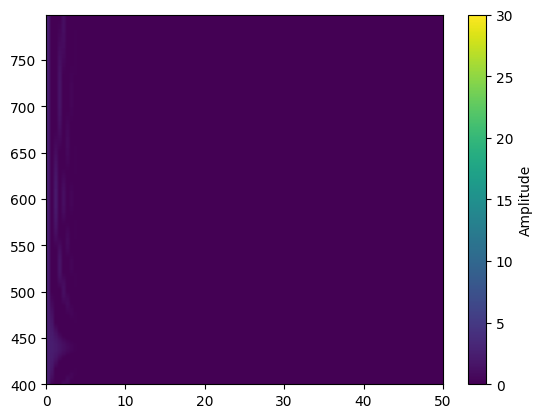

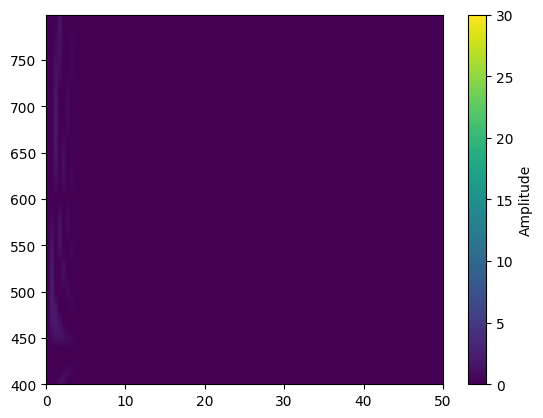

In [4]:
params_dict = {
    # Pulse and dispersion
    "DM": 100.0,           # pc/cm^3
    "tau_ref": 0 ,#0.000, # 0.015,      # s, scatter broadening at freq_ref
    "epsilon": -2.0,        # dispersion exponent
    
    # Temporal shape
    "sigma": 0.1,        # s, intrinsic width of pulse
    
    # Amplitude / spectrum
    "alpha": 1.0,          # log10 global amplitude
    "gamma": 0.0,         # spectral index for SED
    "beta": 0.0,           # running spectral index
    "delta": -4.0,          # scatter-frequency exponent
    "mean_arrival_time": 1.0,
    
}

# fixed / typical values
freq_channels_ref = 600.0
# gamma = 0.0
# beta = 0.0
delta = -4.0
epsilon = -2.0
tau_ref = 0.0 #numpyro.sample(f"tau_ref_{i}", dist.Uniform(0.0, 0.01))
k_DM = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s

constants_dict = {
    "tau_ref": tau_ref,
    "freq_channels_ref": freq_channels_ref,
    "epsilon": epsilon,
    "k_DM": k_DM,
    "delta": -4.0
}

freq_array = jnp.arange(400,800,1, dtype=jnp.float32)[:, None]  # (nfreq,1), MHz
time_array = jnp.arange(1,3,0.01, dtype=jnp.float32)[None, :] # (1,ntime), s
single_pulse_model = setup_model(constants_dict, freq_array, time_array)

M = single_pulse_model(params_dict)

L = time_array[0].shape[0]
dt = time_array[0][1] - time_array[0][0]
fourier_freqs = jnp.fft.rfftfreq(L, d=dt,dtype=jnp.float32)[None, :]


plt.imshow(
    M.real,
    aspect='auto',
    origin='lower',
    extent=[fourier_freqs[0][0], fourier_freqs[0][-1], freq_array.T[0][0], freq_array.T[0][-1]],
    cmap = "viridis",
    vmin=0,
    vmax=30
)
plt.colorbar(label="Amplitude")

plt.figure()
plt.imshow(
    M.imag,
    aspect='auto',
    origin='lower',
    extent=[fourier_freqs[0][0], fourier_freqs[0][-1], freq_array.T[0][0], freq_array.T[0][-1]],
    cmap = "viridis",
    vmin=0,
    vmax=30
)
plt.colorbar(label="Amplitude")

### Going back to Time domain - wraparound can occur if DM is too large, de-dispersion needed before evaluating in Fourier domain

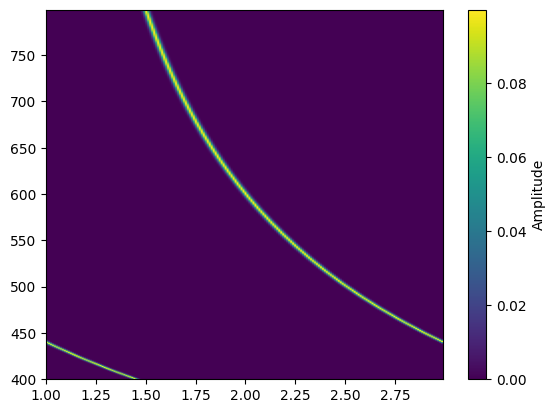

In [5]:
params_dict = {
    # Pulse and dispersion
    "DM": 100.0,           # pc/cm^3
    "tau_ref": 0 ,#0.000, # 0.015,      # s, scatter broadening at freq_ref
    "epsilon": -2.0,        # dispersion exponent
    
    # Temporal shape
    "sigma": 0.01,        # s, intrinsic width of pulse
    
    # Amplitude / spectrum
    "alpha": 1.0,          # log10 global amplitude
    "gamma": 0.0,         # spectral index for SED
    "beta": 0.0,           # running spectral index
    "delta": -4.0,          # scatter-frequency exponent
    "mean_arrival_time": 1.0,
    
}

# fixed / typical values
freq_channels_ref = 600.0
# gamma = 0.0
# beta = 0.0
delta = -4.0
epsilon = -2.0
tau_ref = 0.0 #numpyro.sample(f"tau_ref_{i}", dist.Uniform(0.0, 0.01))
k_DM = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s

constants_dict = {
    "tau_ref": tau_ref,
    "freq_channels_ref": freq_channels_ref,
    "epsilon": epsilon,
    "k_DM": k_DM,
    "delta": -4.0
}

freq_array = jnp.arange(400,800,1, dtype=jnp.float32)[:, None]  # (nfreq,1), MHz
time_array = jnp.arange(1,3,0.01, dtype=jnp.float32)[None, :] # (1,ntime), s
single_pulse_model = setup_model(constants_dict, freq_array, time_array)

M = single_pulse_model(params_dict)

L = time_array[0].shape[0]
dt = time_array[0][1] - time_array[0][0]
fourier_freqs = jnp.fft.rfftfreq(L, d=dt,dtype=jnp.float32)[None, :]

# M *= jnp.exp(2j *jnp.pi * fourier_freqs * 1)

M_td = jnp.fft.irfft(M,axis=-1)


plt.imshow(
    M_td,
    aspect='auto',
    origin='lower',
    cmap = "viridis",
    extent=[time_array[0][0], time_array[0][-1], freq_array.T[0][0], freq_array.T[0][-1]],
)
plt.colorbar(label="Amplitude")


# plt.imshow(
#     M.real,
#     aspect='auto',
#     origin='lower',
#     extent=[fourier_freqs[0][0], fourier_freqs[0][-1], freq_array.T[0][0], freq_array.T[0][-1]],
#     cmap = "viridis",
#     vmin=0,
#     vmax=30
# )
# plt.colorbar(label="Amplitude")

# plt.figure()
# plt.imshow(
#     M.imag,
#     aspect='auto',
#     origin='lower',
#     extent=[fourier_freqs[0][0], fourier_freqs[0][-1], freq_array.T[0][0], freq_array.T[0][-1]],
#     cmap = "viridis",
#     vmin=0,
#     vmax=30
# )
# plt.colorbar(label="Amplitude")

In [6]:
### TO-DO!! Make these funcitons use lax.scan instead of for loop over M_total, and then make frb_forward_model a closure inside of numpyro_model and stack all of the parameters

def frb_forward_model(params_list, len_freq_channel_array, len_fourier_freq_array, single_pulse_method):
    """
    Forward model for multi-pulse FRB as sum of single pulses.

    Parameters
    ----------
    params_list : list of dict
        Each dict contains parameters for a single pulse (as in single_pulse_model).
    params_list : list of dict
        Each dict contains constants for a single pulse (as in single_pulse_model).
    len_freq_channel_array : int
        Number of frequency channels
    len_fourier_freq_array : int
        Number of Fourier frequency bins

    Returns
    -------
    M : array (nfreq, ntime)
        Dynamic spectrum of the summed pulses
    """
    M_total = jnp.zeros((len_freq_channel_array, len_fourier_freq_array))

    # Sum over pulses
    for params_dict in params_list:#(params_dict, constants_dict) in zip(params_list, constants_list):
        M_total += single_pulse_method(params_dict)

    return M_total

def sample_scaled_uniform(name, low, high):
    """
    Sample from Uniform(low, high) via a unit-scale base variable, so NUTS's
    dense mass matrix estimation operates on O(1) values regardless of the
    parameter's true physical scale.
    """
    u = numpyro.sample(f"{name}_base", dist.Uniform(0.0, 1.0))
    value = numpyro.deterministic(name, low + u * (high - low))
    return value

def numpyro_model(data, len_freq_channel_array, len_fourier_freq_array, single_pulse_method, sigma_noise, n_pulses):
    """
    Numpyro model for multi-pulse FRB.
    data: assumed to be FFTd before passed in
    sigma_noise: defined as sqrt(PSD)
    """

    params_list = []

    for i in range(n_pulses):

        ##### 
        # FAKE DATA PRIORS
        #####
        
        # # Priors for pulse i
        # #DM = numpyro.sample(f"DM_{i}", dist.Uniform(0, 500))
        # DM = numpyro.sample(f"DM_{i}", dist.Uniform(-100, 100))
        # #mean_arrival_time = numpyro.sample(f"t0_{i}", dist.Uniform(0.0, 2.0))
        # mean_arrival_time = numpyro.sample(f"t0_{i}", dist.Uniform(-10, 10))
        # sigma = numpyro.sample(f"sigma_{i}", dist.Uniform(0.005, 0.1))
        # alpha = numpyro.sample(f"alpha_{i}", dist.Uniform(0, 2.0))
        # tau_ref = 0 #numpyro.sample(f"tau_ref_{i}", dist.Uniform(0.0, 0.01))
        # gamma = numpyro.sample(f"gamma_{i}", dist.Uniform(-10, 10))
        # beta = numpyro.sample(f"beta_{i}", dist.Uniform(-1, 1))
        # delta = numpyro.sample(f"delta_{i}", dist.Uniform(-4.5, -3.5))
        # epsilon = numpyro.sample(f"epsilon_{i}", dist.Uniform(-2.1, -1.9))

        # # fixed / typical values
        # freq_ref = 600.0
        # # gamma = 0.0
        # # beta = 0.0
        # # delta = -4.0
        # # epsilon = -2.0
        # k_DM = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s
        
        ##### 
        # REAL DATA PRIORS
        #####
        
        # Priors for pulse i
        #DM = numpyro.sample(f"DM_{i}", dist.Uniform(0, 500))
        DM = sample_scaled_uniform(f"DM_{i}", -10, 10)
        #mean_arrival_time = numpyro.sample(f"t0_{i}", dist.Uniform(0.0, 2.0))
        mean_arrival_time = sample_scaled_uniform(f"t0_{i}", -0.02+0.08, 0.02+0.08)
        sigma = sample_scaled_uniform(f"sigma_{i}", 0.1/1000, 10/1000)
        alpha = sample_scaled_uniform(f"alpha_{i}", -2.0, 0.0)
        gamma = sample_scaled_uniform(f"gamma_{i}", -20, 10)
        beta = sample_scaled_uniform(f"beta_{i}", -20, 10)
        tau_ref = sample_scaled_uniform(f"tau_ref_{i}", 0, 0.1)
        #delta = numpyro.sample(f"delta_{i}", dist.Uniform(-4.5, -3.5))
        # epsilon = numpyro.sample(f"epsilon_{i}", dist.Uniform(-2.1, -1.9))

        # {"amplitude": [-1.6610962224298984], "arrival_time": [482488.48689058475], "burst_width": [0.0004128824360633611], 
        #  "dm": [848.8783200451409], "dm_index": [-2.0], "scattering_timescale": [0.01009891957302962], "scattering_index": [-4.0], 
        #  "spectral_index": [2.078152594885448], "spectral_running": [-7.62940918595922], "ref_freq": [400.1953125]}

        
        # # fixed / typical values
        # freq_ref = 600.0
        # # gamma = 0.0
        # # beta = 0.0
        # delta = -4.0
        # epsilon = -2.0
        # tau_ref = 0.0 #numpyro.sample(f"tau_ref_{i}", dist.Uniform(0.0, 0.01))
        # k_DM = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s

        params_dict = {
            "DM": DM,
            "mean_arrival_time": mean_arrival_time,
            "sigma": sigma,
            "alpha": alpha,
            "gamma": gamma,
            "beta": beta,
            "tau_ref":tau_ref
        }

        # constants_dict = {
        #     "tau_ref": tau_ref,
        #     "freq_ref": freq_ref,
        #     "epsilon": epsilon,
        #     "k_DM": k_DM
        # }

        params_list.append(params_dict)
        # constants_list.append(constants_dict)

    # Forward model: sum of pulses
    pred = frb_forward_model(params_list, len_freq_channel_array, len_fourier_freq_array, single_pulse_method)    

    # Now we stack real and imaginary components of our data and model into shape (2, channels, fourier_freqs).
    # This is because the numpyro likelihood can't handle complex quantities, but we can rewrite the norm of the residual
    # of complex quantities in terms of separated residuals of the real and imag parts.
    data_stacked = jnp.stack([jnp.real(data), jnp.imag(data)], axis=0)
    pred_stacked = jnp.stack([jnp.real(pred), jnp.imag(pred)], axis=0)

    # Broadcast the PSD to shape (2, channels, fourier_freqs).
    sigma_stacked = jnp.broadcast_to(sigma_noise[None, :, :], data_stacked.shape)

    # Sample from likelihood (Gaussian noise)
    numpyro.sample("obs", dist.Normal(pred_stacked, sigma_stacked), obs=data_stacked)


## Real data

#### Pulling the data

In [7]:
filename = "FRB20190710B_stokesi_dynamic_spectrum.h5"

with h5py.File(filename, "r") as handler:

    print(handler.attrs.keys())
    
    event_id = handler.attrs["event_id"]
    freq = handler["index_map"]["freqs"][:]
    
    toa = json.loads(handler.attrs["burst_parameters_json"])["arrival_time"]
    time = (handler["index_map"]["times"][:] - np.mean(toa))

    good_freq = handler["good_freq"][:]
    flag = handler["flag"][:]
        
    data = handler["data"][:]
    
    print(handler.attrs["burst_parameters_json"])

<KeysViewHDF5 ['beam_number', 'burst_parameters_json', 'catalog', 'center_time', 'contact', 'creator', 'datatype', 'dm_const', 'dm_incoherent', 'dm_index', 'doi', 'event_id', 'freqs_bin0', 'instrument', 'is_dedispersed', 'num_freq', 'num_time', 'pipeline_parameters_json', 'pulse_emission_region', 'ref_freq', 'repeater_name', 'res_freq', 'res_time', 'start_time_unix_nano', 'stokes', 'telescope', 'times_bin0', 'tns_name', 'unwindowed_num_time', 'unwindowed_times_bin0']>
{"amplitude": [-2.4384073346617754], "arrival_time": [67188.58150523654], "burst_width": [0.00023005851906412734], "dm": [260.40078048865473], "dm_index": [-2.0], "scattering_timescale": [0.003078585128672799], "scattering_index": [-4.0], "spectral_index": [18.157461916804742], "spectral_running": [-55.3169992784899], "ref_freq": [400.1953125]}


In [8]:
# filename = "FRB20180730A_stokesi_dynamic_spectrum.h5"

# with h5py.File(filename, "r") as handler:

#     print(handler.attrs.keys())
    
#     event_id = handler.attrs["event_id"]
#     freq = handler["index_map"]["freqs"][:]
    
#     toa = json.loads(handler.attrs["burst_parameters_json"])["arrival_time"]
#     time = (handler["index_map"]["times"][:] - np.mean(toa))

#     good_freq = handler["good_freq"][:]
#     flag = handler["flag"][:]
        
#     data = handler["data"][:]
    
#     print(handler.attrs["burst_parameters_json"])

#### Downsampling data

In [9]:
def bin_freq_channels(data, fbin_factor=4):
    num_chan = data.shape[0]
    if num_chan % fbin_factor != 0:
        raise ValueError("frequency binning factor `fbin_factor` should be even")
    data = np.nanmean(data.reshape((num_chan // fbin_factor, fbin_factor) + data.shape[1:]), axis=1)
    return data


def bin_freq_boolean(arr, fbin_factor=4):
    n = arr.shape[0]
    if n % fbin_factor != 0:
        raise ValueError("frequency binning factor must divide number of channels")

    arr = arr.reshape((n // fbin_factor, fbin_factor) + arr.shape[1:])
    return np.any(arr, axis=1)

binning_factor = 2**4
flag = bin_freq_boolean(flag, fbin_factor=binning_factor)
good_freq = bin_freq_boolean(good_freq, fbin_factor=binning_factor)
data = bin_freq_channels(data, fbin_factor=binning_factor)

combined_flag = flag & good_freq[:, jnp.newaxis]

Downsampling gives us a mask of bad frequencies, we'll apply the mask directly to the data to remove masked frequencies before analyzing. The model will also be passed an array of masked frequency values.

In [10]:
mask_matrix = np.repeat(good_freq[None, :], data.shape[1], axis=0)
mask_matrix=mask_matrix.T

In [11]:
freq_array = jnp.arange(freq[0],freq[-1],(freq[-1]-freq[0])/data.shape[0], dtype=jnp.float32)[:, None]  # (nfreq,1), MHz
freq_array_reshaped = freq_array[good_freq]

time_array = jnp.arange(time[0],time[-1],(time[-1]-time[0])/data.shape[1], dtype=jnp.float32)[None, :]  # (1,ntime), ms

data_reshaped = data[mask_matrix].reshape(freq_array_reshaped.shape[0],time_array.shape[1])

First plotting data with masked channels included
Then plotting data with masked channels removed


Text(0, 0.5, 'Frequency [MHz]')

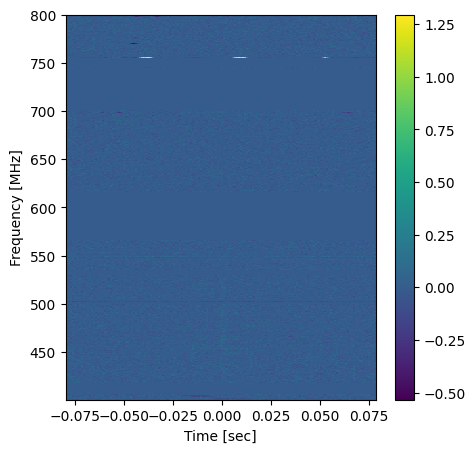

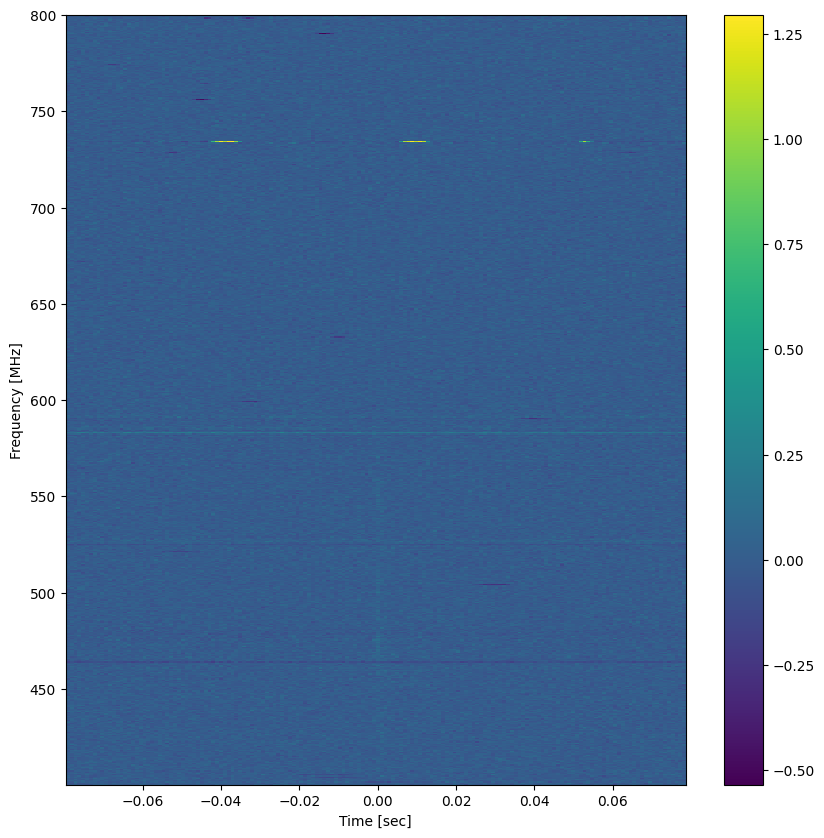

In [12]:
print("First plotting data with masked channels included")

fig = plt.figure(figsize=(5, 5))
img = plt.imshow(data * combined_flag,
                 aspect="auto",
                 origin="lower",
                 interpolation="nearest",
                 extent=(time[0], time[-1], freq[0], freq[-1]))
plt.colorbar(img)

# plt.xlabel("Time [msec]")
plt.xlabel("Time [sec]")
plt.ylabel("Frequency [MHz]")

print("Then plotting data with masked channels removed")

fig = plt.figure(figsize=(10, 10))
img = plt.imshow(data_reshaped,
                 aspect="auto",
                 origin="lower",
                 interpolation="nearest",
                 extent=(time[0], time[-1], freq[0], freq[-1]))
plt.colorbar(img)

# plt.xlabel("Time [msec]")
plt.xlabel("Time [sec]")
plt.ylabel("Frequency [MHz]")

#### Estimating noise

In [13]:
times_noise = jnp.asarray([i for i in time_array[0] if i<-10/1000]).flatten()
noise_data = data_reshaped[:,0:len(times_noise)]

len(times_noise)

72

Noise segments we will draw from


Text(0, 0.5, 'Frequency [MHz]')

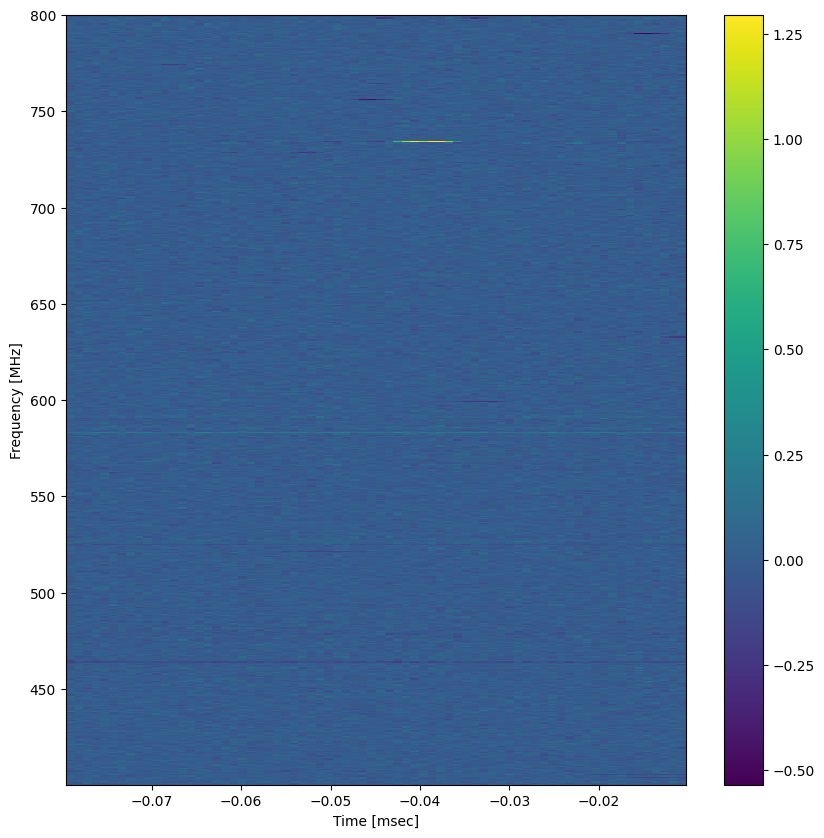

In [14]:
print("Noise segments we will draw from")
fig = plt.figure(figsize=(10, 10))
img = plt.imshow(noise_data,
                 aspect="auto",
                 origin="lower",
                 interpolation="nearest",
                 extent=(times_noise[0], times_noise[-1], freq[0], freq[-1]))
plt.colorbar(img)

plt.xlabel("Time [msec]")
plt.ylabel("Frequency [MHz]")

In [15]:
noise_median_estimates = jnp.asarray([jnp.median(data_reshaped[i,0:len(times_noise)]) for i in jnp.arange(len(freq_array_reshaped))])[:,None]


(array([  1.,   1.,   5., 550.,  75.,   2.,   0.,   0.,   0.,   1.]),
 array([-0.10626884, -0.0780783 , -0.04988777, -0.02169724,  0.0064933 ,
         0.03468384,  0.06287436,  0.0910649 ,  0.11925544,  0.14744596,
         0.17563652]),
 <BarContainer object of 10 artists>)

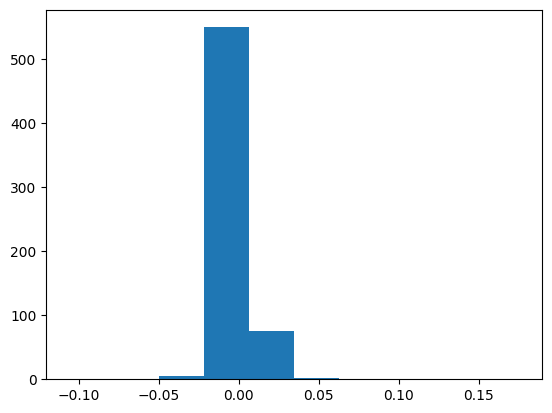

In [16]:
plt.hist(noise_median_estimates)

In [17]:
# 1. Calculate the median per frequency row
median = jnp.median(noise_data, axis=1, keepdims=True)

# 2. Calculate MAD: median(|x - median|)
mad = jnp.median(jnp.abs(noise_data - median), axis=1, keepdims=True)

# 3. Convert to sigma (1.4826 is the scaling factor for Normal dists)
sigma_estimates = mad * 1.4826

# Ensure no zeros (numerical floor)
sigma_estimates = jnp.clip(sigma_estimates, a_min=1e-10)

(array([ 15.,  60., 124., 153., 140.,  97.,  30.,  10.,   3.,   3.]),
 array([0.02391006, 0.02728723, 0.0306644 , 0.03404157, 0.03741874,
        0.04079591, 0.04417308, 0.04755025, 0.05092742, 0.05430459,
        0.05768177]),
 <BarContainer object of 10 artists>)

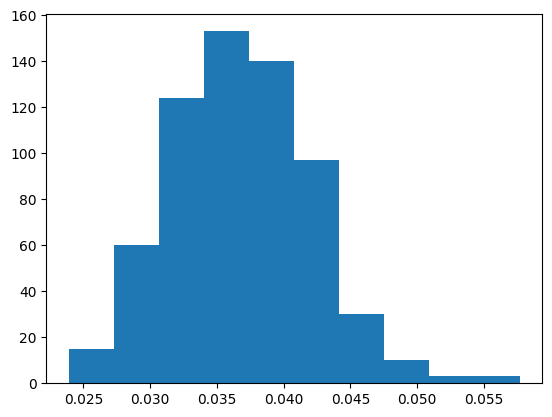

In [18]:
plt.hist(sigma_estimates)

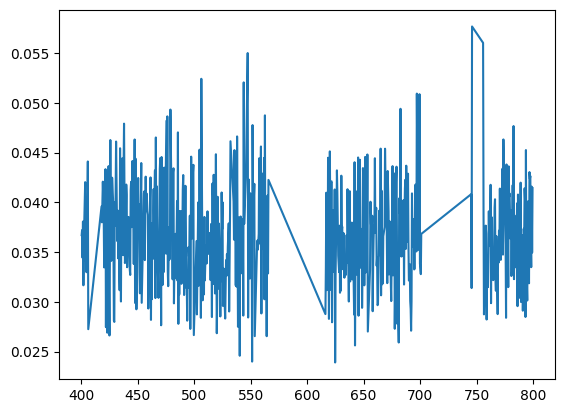

In [19]:
plt.plot(freq_array_reshaped, sigma_estimates)

#### Subtracting Noise Median from Data

In [20]:
data_reshaped = data_reshaped-noise_median_estimates

Text(0, 0.5, 'Frequency [MHz]')

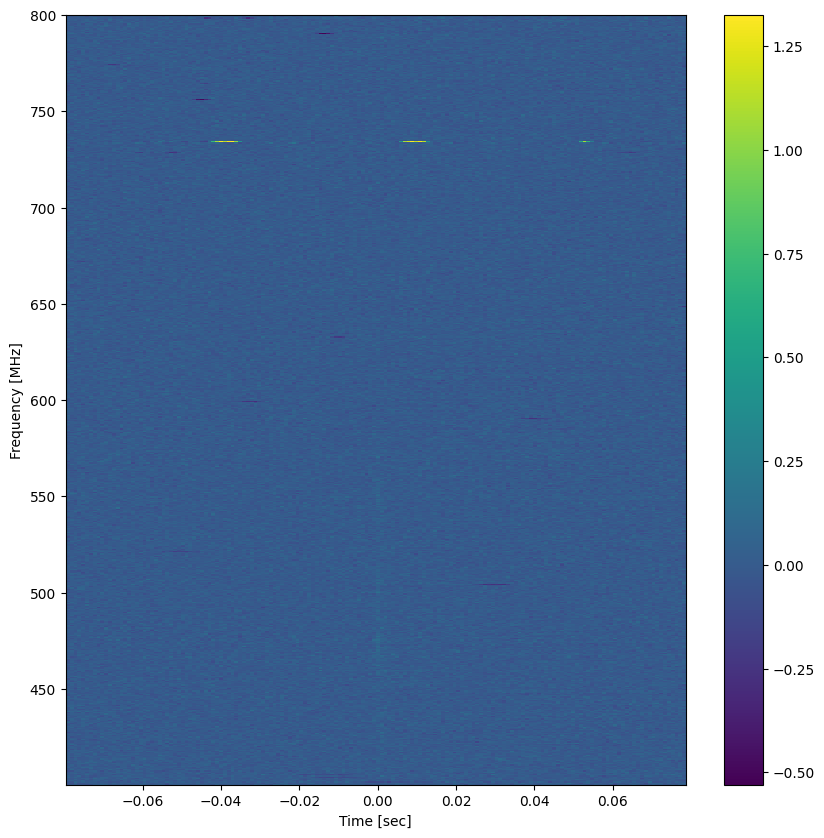

In [21]:
fig = plt.figure(figsize=(10, 10))
img = plt.imshow(data_reshaped,
                 aspect="auto",
                 origin="lower",
                 interpolation="nearest",
                 extent=(time[0], time[-1], freq[0], freq[-1]))
plt.colorbar(img)

# plt.xlabel("Time [msec]")
plt.xlabel("Time [sec]")
plt.ylabel("Frequency [MHz]")

#### Further truncating data for computational convenience

In [22]:
# print("First plotting data with masked channels included")

# fig = plt.figure(figsize=(10, 10))
# img = plt.imshow(data * combined_flag,
#                  aspect="auto",
#                  origin="lower",
#                  interpolation="nearest",
#                  extent=(time[0], time[-1], freq[0], freq[-1]))
# plt.colorbar(img)

# # plt.xlabel("Time [msec]")
# plt.xlabel("Time [sec]")
# plt.ylabel("Frequency [MHz]")

# print("Then plotting data with masked channels removed")

# time_slice = [70,100]
# fig = plt.figure(figsize=(10, 10))
# img = plt.imshow(data_reshaped[:,time_slice[0]:time_slice[1]],
#                  aspect="auto",
#                  origin="lower",
#                  interpolation="nearest",
#                 extent=(time[time_slice[0]], time[time_slice[1]], freq[0], freq[-1]))
# plt.colorbar(img)

# # plt.xlabel("Time [msec]")
# plt.xlabel("Time [sec]")
# plt.ylabel("Frequency [MHz]")

In [23]:
# data_reshaped = data_reshaped[:,70:100]
# time_array = time_array[:,70:100]

#### Fourier transforming the data

In [24]:
L = time_array[0].shape[0]
dt = time_array[0][1] - time_array[0][0]
fourier_freqs = jnp.fft.rfftfreq(L, d=dt,dtype=jnp.float32)

In [25]:
data_reshaped_FFT = dt * jnp.fft.rfft(data_reshaped,axis=-1)

## Run model

#### Running model

In [26]:
### Defining necessary constants

# fixed / typical values
freq_channels_ref = 600.0
# gamma = 0.0
# beta = 0.0
delta = -4.0
epsilon = -2.0
# tau_ref = 0.0 #numpyro.sample(f"tau_ref_{i}", dist.Uniform(0.0, 0.01))
k_DM = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s

constants_dict = {
    "freq_channels_ref": freq_channels_ref,
    "epsilon": epsilon,
    "k_DM": k_DM,
    "delta": delta
    #"tau_ref": tau_ref
}

len_freq_channel_array = len(freq_array_reshaped)
len_fourier_freq_array = len(fourier_freqs)

# define PSD
eta = 2*jnp.ones(len_fourier_freq_array)
eta = eta.at[0].set(1.0)
if L%2==0:
    eta = eta.at[-1].set(1.0)
PSD = eta * L * (dt**2) * sigma_estimates**2
sqrtPSD = jnp.sqrt(PSD)

In [27]:
init_vals_physical = {'DM_0_base': 0.5000082,
 't0_0_base': 0.46453488,
 'sigma_0_base': 0.05679487,
 'alpha_0_base': 0.63847893,
 'gamma_0_base': 0.53103894,
 'beta_0_base': 0.4419631,
 'tau_ref_0_base': 0.02193132}

In [28]:
### setting up model method
single_pulse_method = setup_model(constants_dict, freq_array_reshaped, time_array)

#running sampler

kernel = NUTS(numpyro_model, dense_mass=True)#, init_strategy=init_to_value(values=init_vals_physical))
seed = 1
rng_key = jrand.PRNGKey(seed)

num_samples = 500
num_warmup = 500
num_chains = 4
mcmc = MCMC(kernel, num_warmup=num_warmup, num_samples=num_samples, num_chains=num_chains, chain_method="parallel" )


In [29]:
mcmc.run(rng_key=rng_key, data=data_reshaped_FFT, len_freq_channel_array=len_freq_channel_array, len_fourier_freq_array=len_fourier_freq_array, single_pulse_method = single_pulse_method, sigma_noise = sqrtPSD, n_pulses=1,extra_fields=("num_steps","accept_prob","diverging","potential_energy"))


Compiling.. :   0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

Compiling.. :   0%|          | 0/1000 [00:00<?, ?it/s]


  0%|          | 0/1000 [00:00<?, ?it/s]


Running chain 1:   0%|          | 0/1000 [00:03<?, ?it/s]

Running chain 2:   0%|          | 0/1000 [00:03<?, ?it/s]


Running chain 0:   5%|▌         | 50/1000 [00:05<00:47, 20.04it/s]


Running chain 3:   5%|▌         | 50/1000 [00:14<03:41,  4.29it/s]

Running chain 0:  15%|█▌        | 150/1000 [00:37<03:11,  4.45it/s][A


Running chain 0:  30%|███       | 300/1000 [00:41<00:56, 12.31it/s]


Running chain 0:  35%|███▌      | 350/1000 [00:44<00:46, 14.08it/s]

Running chain 2:  10%|█         | 100/1000 [00:45<06:46,  2.21it/s]


Running chain 0:  45%|████▌     | 450/1000 [00:46<00:24, 22.36it/s]


Running chain 0:  55%|█████▌    | 550/1000 [00:48<00:14, 30.27it/s]


Running chain 3:  30%|███       | 300/1000 [00:49<01:04, 10.87it/s]

Running chain 0:  60%|██████    | 600/1000 [00:49<00:11,

In [30]:
extra = mcmc.get_extra_fields()
print("total steps:", extra["num_steps"].sum())
print("mean steps:", extra["num_steps"].mean())
print("max steps:", extra["num_steps"].max())
print("accept prob:",extra["accept_prob"].mean())
print("diverging",extra["diverging"].sum())


total steps: 37197
mean steps: 18.598501
max steps: 95
accept prob: 0.8627393
diverging 2


In [31]:
mcmc_data = az.from_numpyro(mcmc, log_likelihood={}, posterior_predictive={})

In [32]:
az.summary(mcmc_data, round_to=3)

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
DM_0,0.000,0.057,-0.106,0.112,0.002,0.002,1217.086,1041.749,1.003
DM_0_base,0.500,0.003,0.495,0.506,0.000,0.000,1217.086,1041.749,1.003
alpha_0,-1.675,0.203,-1.982,-1.284,0.008,0.006,528.393,489.065,1.002
alpha_0_base,0.163,0.101,0.009,0.358,0.004,0.003,528.393,489.065,1.002
beta_0,-17.290,2.355,-20.000,-13.081,0.074,0.065,643.780,645.771,1.006
beta_0_base,0.090,0.079,0.000,0.231,0.002,0.002,643.772,645.771,1.006
gamma_0,-10.176,1.385,-12.830,-7.552,0.045,0.038,936.778,1054.802,1.006
gamma_0_base,0.327,0.046,0.239,0.415,0.002,0.001,936.778,1054.802,1.006
sigma_0,0.000,0.000,0.000,0.001,0.000,0.000,582.528,398.547,1.003
sigma_0_base,0.036,0.022,0.001,0.073,0.001,0.001,582.528,398.547,1.003


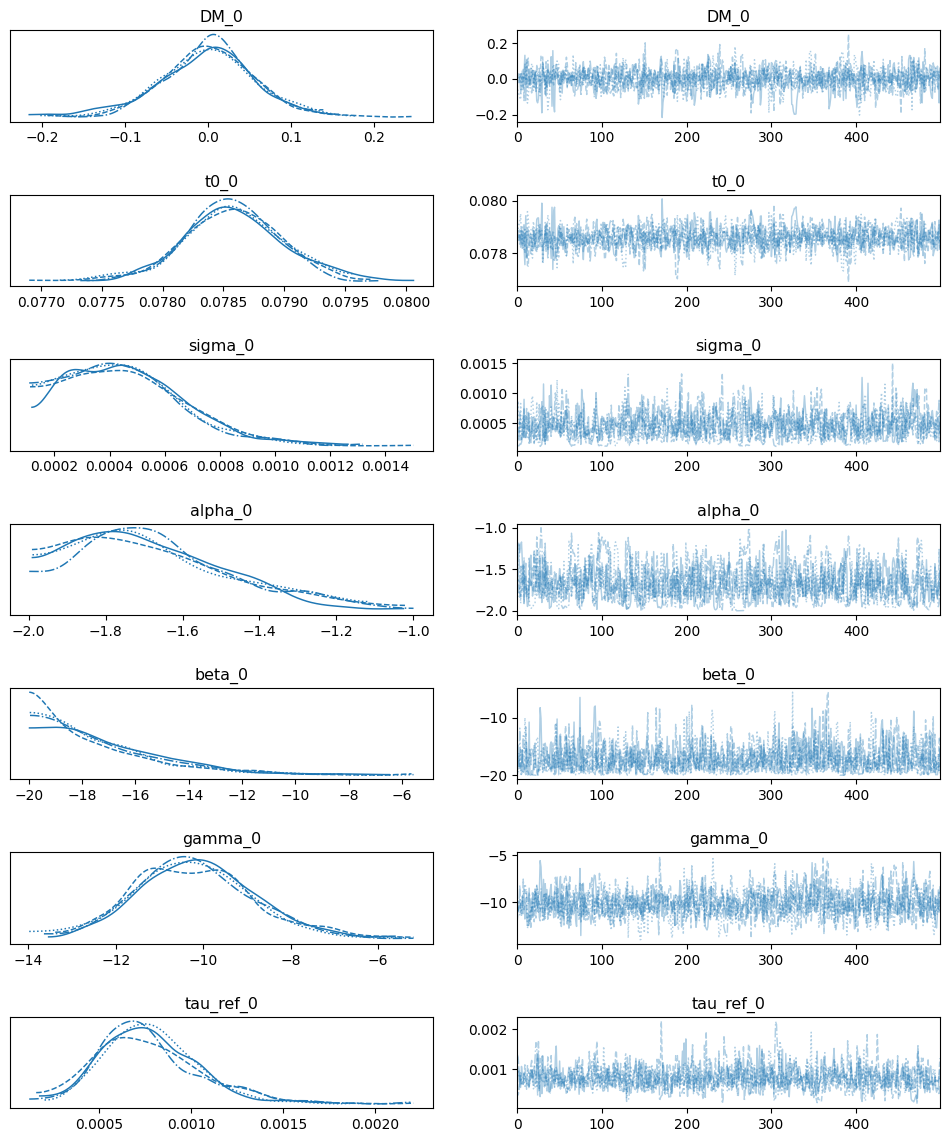

In [33]:
axes = az.plot_trace(mcmc_data, var_names=["DM_0", "t0_0", "sigma_0", "alpha_0", "beta_0", "gamma_0", "tau_ref_0"],combined=False,divergences=False);
# axes = az.plot_trace(mcmc_data, var_names=["DM_0", "t0_0", "sigma_0", "alpha_0", "beta_0", "gamma_0"],combined=False,divergences=False);

# for i, var in enumerate(["DM_0", "t0_0", "sigma_0", "alpha_0"]):
#     # posterior panel only
#     axes[i, 0].axvline(true_vals[var], color="black", linestyle="--", lw=2)
    
plt.subplots_adjust(hspace=0.8)  # increase vertical spacing

#### Plotting model with posterior draws

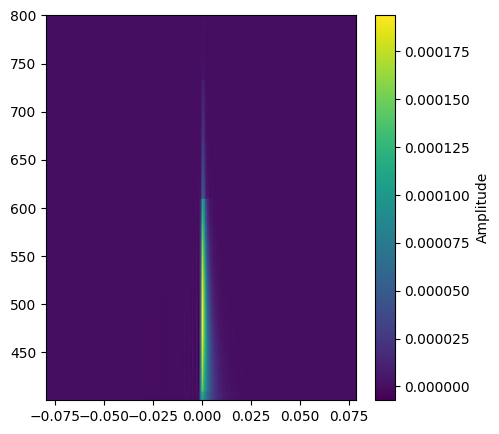

In [34]:
draw = 220
chain = 0

params_dict = {
    # Pulse and dispersion
    "DM": mcmc_data.posterior.sel(chain=chain, draw=draw).DM_0.values[()],           # pc/cm^3
    "freq_ref": 600.0,     # MHz, reference frequency near middle of band
    "tau_ref": mcmc_data.posterior.sel(chain=chain, draw=draw).tau_ref_0.values[()], # mcmc_data.posterior.sel(chain=0, draw=0).tau_ref_0.values[()],#0.000, # 0.015,      # s, scatter broadening at freq_ref
    "epsilon": -2.0,        # dispersion exponent
    
    # Temporal shape
    "sigma": mcmc_data.posterior.sel(chain=chain, draw=draw).sigma_0.values[()],        # s, intrinsic width of pulse
    
    # Amplitude / spectrum
    "alpha": mcmc_data.posterior.sel(chain=chain, draw=draw).alpha_0.values[()],          # log10 global amplitude
    "gamma": mcmc_data.posterior.sel(chain=chain, draw=draw).gamma_0.values[()],         # spectral index for SED
    "beta": mcmc_data.posterior.sel(chain=chain, draw=draw).beta_0.values[()],           # running spectral index
    "delta": -4.0,          # scatter-frequency exponent
    "mean_arrival_time": mcmc_data.posterior.sel(chain=chain, draw=draw).t0_0.values[()],
    "k_DM": (2.41*1e-4)**(-1)
}

# fixed / typical values
freq_channels_ref = 600.0
# gamma = 0.0
# beta = 0.0
delta = -4.0
epsilon = -2.0
tau_ref = 0.0 #numpyro.sample(f"tau_ref_{i}", dist.Uniform(0.0, 0.01))
k_DM = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s

constants_dict = {
    "freq_channels_ref": freq_channels_ref,
    "epsilon": epsilon,
    "k_DM": k_DM,
    "delta": delta,
    "tau_ref": tau_ref
}

# freq_array = jnp.arange(400,800,1, dtype=jnp.float32)[:, None]  # (nfreq,1), MHz
# time_array = jnp.arange(1,3,0.01, dtype=jnp.float32)[None, :] # (1,ntime), s
# #single_pulse_model(params_dict, freq_array, time_array)
single_pulse_method = setup_model(constants_dict, freq_array_reshaped, time_array)

M = single_pulse_method(params_dict)
M_TD_sampled = 1/(L*dt) * jnp.fft.irfft(M,axis=-1)
fig = plt.figure(figsize=(5, 5))
plt.imshow(
    M_TD_sampled,
    aspect='auto',
    origin='lower',
    cmap = "viridis",
    extent=(time[0], time[-1], freq[0], freq[-1])
)
plt.colorbar(label="Amplitude")


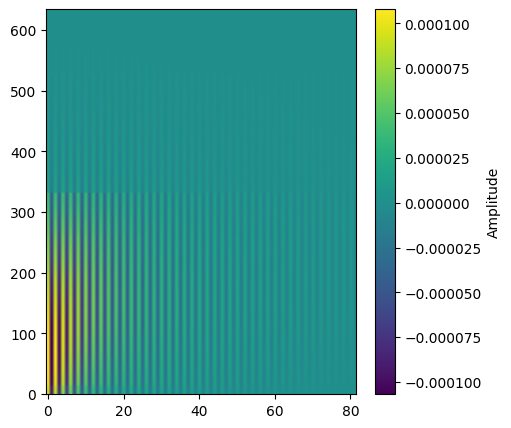

In [35]:
draw = 220
chain = 0

params_dict = {
    # Pulse and dispersion
    "DM": mcmc_data.posterior.sel(chain=chain, draw=draw).DM_0.values[()],           # pc/cm^3
    "freq_ref": 600.0,     # MHz, reference frequency near middle of band
    "tau_ref": mcmc_data.posterior.sel(chain=chain, draw=draw).tau_ref_0.values[()], # mcmc_data.posterior.sel(chain=0, draw=0).tau_ref_0.values[()],#0.000, # 0.015,      # s, scatter broadening at freq_ref
    "epsilon": -2.0,        # dispersion exponent
    
    # Temporal shape
    "sigma": mcmc_data.posterior.sel(chain=chain, draw=draw).sigma_0.values[()],        # s, intrinsic width of pulse
    
    # Amplitude / spectrum
    "alpha": mcmc_data.posterior.sel(chain=chain, draw=draw).alpha_0.values[()],          # log10 global amplitude
    "gamma": mcmc_data.posterior.sel(chain=chain, draw=draw).gamma_0.values[()],         # spectral index for SED
    "beta": mcmc_data.posterior.sel(chain=chain, draw=draw).beta_0.values[()],           # running spectral index
    "delta": -4.0,          # scatter-frequency exponent
    "mean_arrival_time": mcmc_data.posterior.sel(chain=chain, draw=draw).t0_0.values[()],
    "k_DM": (2.41*1e-4)**(-1)
}

# fixed / typical values
freq_channels_ref = 600.0
# gamma = 0.0
# beta = 0.0
delta = -4.0
epsilon = -2.0
tau_ref = 0.0 #numpyro.sample(f"tau_ref_{i}", dist.Uniform(0.0, 0.01))
k_DM = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s

constants_dict = {
    "freq_channels_ref": freq_channels_ref,
    "epsilon": epsilon,
    "k_DM": k_DM,
    "delta": delta,
    "tau_ref": tau_ref
}

# freq_array = jnp.arange(400,800,1, dtype=jnp.float32)[:, None]  # (nfreq,1), MHz
# time_array = jnp.arange(1,3,0.01, dtype=jnp.float32)[None, :] # (1,ntime), s
# #single_pulse_model(params_dict, freq_array, time_array)
single_pulse_method = setup_model(constants_dict, freq_array_reshaped, time_array)

M = single_pulse_method(params_dict)
M_TD_sampled = 1/(L*dt) * jnp.fft.irfft(M,axis=-1)
fig = plt.figure(figsize=(5, 5))
plt.imshow(
    M.real,
    aspect='auto',
    origin='lower',
    cmap = "viridis"
)
plt.colorbar(label="Amplitude")


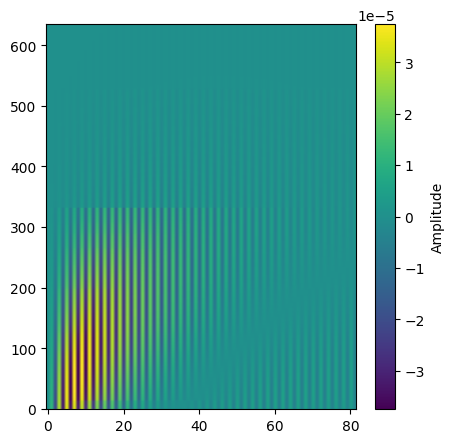

In [36]:
draw = 220
chain = 0

params_dict = {
    # Pulse and dispersion
    "DM": mcmc_data.posterior.sel(chain=chain, draw=draw).DM_0.values[()],           # pc/cm^3
    "freq_ref": 600.0,     # MHz, reference frequency near middle of band
    "tau_ref": mcmc_data.posterior.sel(chain=chain, draw=draw).tau_ref_0.values[()], # mcmc_data.posterior.sel(chain=0, draw=0).tau_ref_0.values[()],#0.000, # 0.015,      # s, scatter broadening at freq_ref
    "epsilon": -2.0,        # dispersion exponent
    
    # Temporal shape
    "sigma": mcmc_data.posterior.sel(chain=chain, draw=draw).sigma_0.values[()],        # s, intrinsic width of pulse
    
    # Amplitude / spectrum
    "alpha": mcmc_data.posterior.sel(chain=chain, draw=draw).alpha_0.values[()],          # log10 global amplitude
    "gamma": mcmc_data.posterior.sel(chain=chain, draw=draw).gamma_0.values[()],         # spectral index for SED
    "beta": mcmc_data.posterior.sel(chain=chain, draw=draw).beta_0.values[()],           # running spectral index
    "delta": -4.0,          # scatter-frequency exponent
    "mean_arrival_time": mcmc_data.posterior.sel(chain=chain, draw=draw).t0_0.values[()],
    "k_DM": (2.41*1e-4)**(-1)
}

# fixed / typical values
freq_channels_ref = 600.0
# gamma = 0.0
# beta = 0.0
delta = -4.0
epsilon = -2.0
tau_ref = 0.0 #numpyro.sample(f"tau_ref_{i}", dist.Uniform(0.0, 0.01))
k_DM = (2.41*1e-4)**(-1) #pc^-1 * cm^3 * GHz^2 * s

constants_dict = {
    "freq_channels_ref": freq_channels_ref,
    "epsilon": epsilon,
    "k_DM": k_DM,
    "delta": delta,
    "tau_ref": tau_ref
}

# freq_array = jnp.arange(400,800,1, dtype=jnp.float32)[:, None]  # (nfreq,1), MHz
# time_array = jnp.arange(1,3,0.01, dtype=jnp.float32)[None, :] # (1,ntime), s
# #single_pulse_model(params_dict, freq_array, time_array)
single_pulse_method = setup_model(constants_dict, freq_array_reshaped, time_array)

M = single_pulse_method(params_dict)
M_TD_sampled = 1/(L*dt) * jnp.fft.irfft(M,axis=-1)
fig = plt.figure(figsize=(5, 5))
plt.imshow(
    M.imag,
    aspect='auto',
    origin='lower',
    cmap = "viridis"
)
plt.colorbar(label="Amplitude")


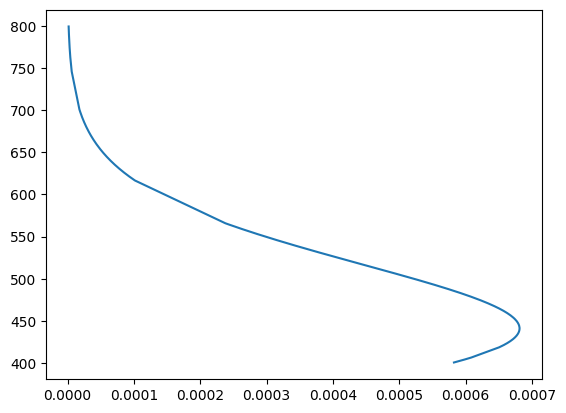

In [37]:
F = jnp.sum(M_TD_sampled, axis=1)
plt.plot(F,freq_array_reshaped)

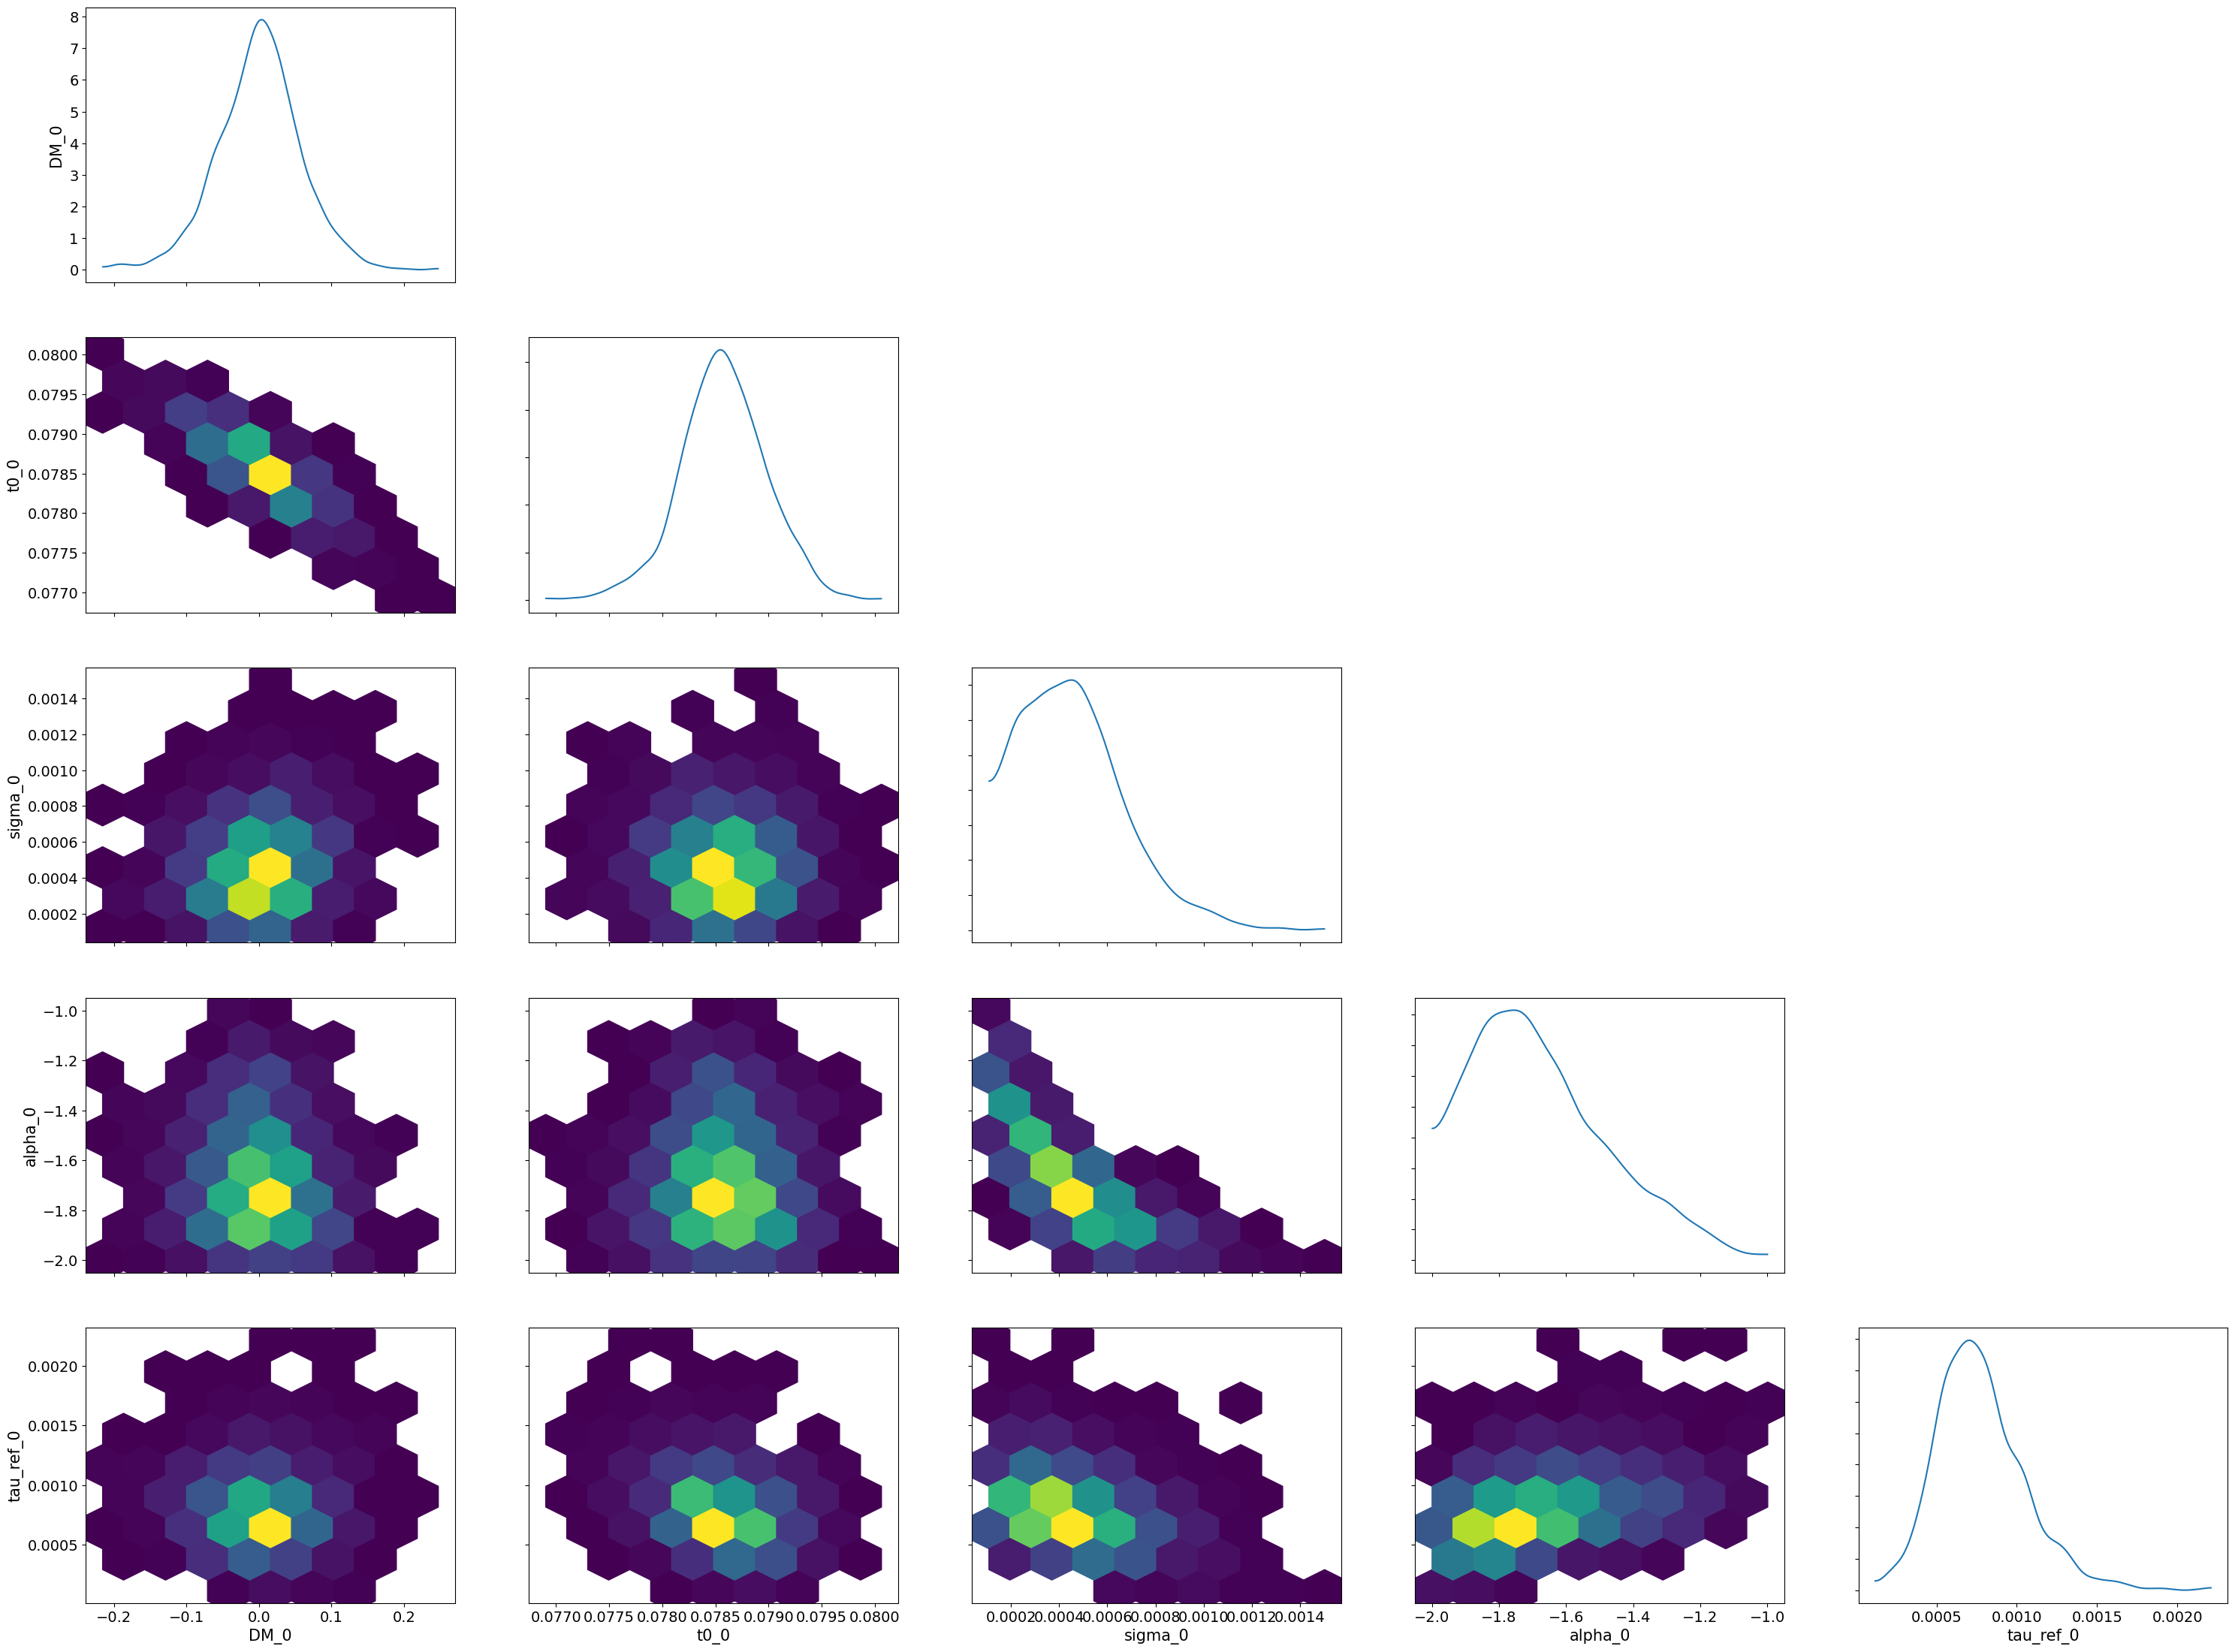

In [38]:
az.plot_pair(
    mcmc_data,
    var_names=["DM_0", "t0_0", "sigma_0", "alpha_0", "tau_ref_0" ],#, "DM_1", "t0_1", "sigma_1", "alpha_1"],
    kind="hexbin",
    marginals=True
);